In [ ]:
{
 "cells": [],
 "metadata": {},
 "nbformat": 4,
 "nbformat_minor": 5
}

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.linalg import eigvals, svdvals
from scipy.sparse import diags

In [14]:
# ---------------------------------------------------------
# Figure output directory
# ---------------------------------------------------------

FIGURE_DIR = Path("../results/figures/matrix_analysis")

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Figures will be saved to:")
print(FIGURE_DIR.resolve())

Figures will be saved to:
C:\Users\TinasheHando\Desktop\2026 Research\quantum-vlasov-poisson\results\figures\matrix_analysis


In [2]:
# ---------------------------------------------------------
# Small velocity grid for quantum-ready matrix analysis
# ---------------------------------------------------------

k = 0.5

v_min = -6.0
v_max = 6.0

Nv = 32

v = np.linspace(v_min, v_max, Nv)
dv = (v_max - v_min) / (Nv - 1)

print("k       =", k)
print("Nv      =", Nv)
print("v_min   =", v_min)
print("v_max   =", v_max)
print("dv      =", dv)

k       = 0.5
Nv      = 32
v_min   = -6.0
v_max   = 6.0
dv      = 0.3870967741935484


In [3]:
# ---------------------------------------------------------
# Maxwellian equilibrium
# ---------------------------------------------------------

f0 = (1.0 / np.sqrt(2.0 * np.pi)) * np.exp(-v**2 / 2.0)

# Analytical derivative:
# df0/dv = -v * f0
df0_dv = -v * f0

print("f0 shape     :", f0.shape)
print("df0/dv shape :", df0_dv.shape)
print("f0 integral  :", np.trapezoid(f0, v))

f0 shape     : (32,)
df0/dv shape : (32,)
f0 integral  : 0.9999999971843628


In [4]:
# ---------------------------------------------------------
# Trapezoidal quadrature weights
# ---------------------------------------------------------

w = np.full(Nv, dv)

w[0] *= 0.5
w[-1] *= 0.5

print("First weight :", w[0])
print("Interior     :", w[1])
print("Last weight  :", w[-1])
print("Weight sum   :", np.sum(w))

First weight : 0.1935483870967742
Interior     : 0.3870967741935484
Last weight  : 0.1935483870967742
Weight sum   : 12.0


In [5]:
# ---------------------------------------------------------
# Linearized Vlasov-Poisson matrix
# ---------------------------------------------------------

V = np.diag(v)

M_k = (
    -1j * k * V
    + (1.0 / (1j * k)) * np.outer(df0_dv, w)
)

print("M_k shape:", M_k.shape)
print("M_k dtype:", M_k.dtype)

M_k shape: (32, 32)
M_k dtype: complex128


In [6]:
# ---------------------------------------------------------
# Inspect matrix structure
# ---------------------------------------------------------

np.set_printoptions(precision=3, suppress=True)

print("Top-left 6x6 block of M_k:\n")
print(M_k[:6, :6])

Top-left 6x6 block of M_k:

[[0.+3.j    0.-0.j    0.-0.j    0.-0.j    0.-0.j    0.-0.j   ]
 [0.-0.j    0.+2.806j 0.-0.j    0.-0.j    0.-0.j    0.-0.j   ]
 [0.-0.j    0.-0.j    0.+2.613j 0.-0.j    0.-0.j    0.-0.j   ]
 [0.-0.j    0.-0.j    0.-0.j    0.+2.419j 0.-0.j    0.-0.j   ]
 [0.-0.j    0.-0.j    0.-0.j    0.-0.j    0.+2.226j 0.-0.j   ]
 [0.-0.j    0.-0.j    0.-0.j    0.-0.j    0.-0.j    0.+2.032j]]


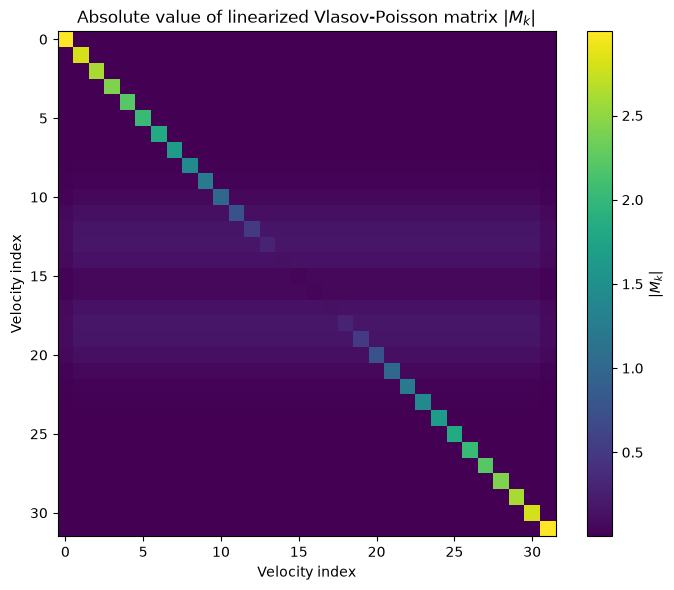

In [15]:
# ---------------------------------------------------------
# Visualize matrix magnitude
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    np.abs(M_k),
    aspect="auto"
)

fig.colorbar(
    im,
    ax=ax,
    label=r"$|M_k|$"
)

ax.set_xlabel("Velocity index")
ax.set_ylabel("Velocity index")
ax.set_title(
    r"Absolute value of linearized Vlasov-Poisson matrix $|M_k|$"
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "matrix_magnitude_Nv32_k0p5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# ---------------------------------------------------------
# Basic matrix diagnostics
# ---------------------------------------------------------

matrix_norm = np.linalg.norm(M_k, ord=2)

hermiticity_error = np.linalg.norm(
    M_k - M_k.conj().T,
    ord=2
)

relative_hermiticity_error = (
    hermiticity_error / matrix_norm
)

print("Matrix 2-norm                :", matrix_norm)
print("Hermiticity error            :", hermiticity_error)
print("Relative Hermiticity error   :", relative_hermiticity_error)

Matrix 2-norm                : 3.184373477379818
Hermiticity error            : 6.012856402672417
Relative Hermiticity error   : 1.8882384385452005


In [9]:
# ---------------------------------------------------------
# Singular-value analysis
# ---------------------------------------------------------

singular_values = svdvals(M_k)

print("Largest singular value :", singular_values[0])
print("Smallest singular value:", singular_values[-1])
print("Condition number       :", singular_values[0] / singular_values[-1])

Largest singular value : 3.184373477379818
Smallest singular value: 0.0967741935483869
Condition number       : 32.905192599591516


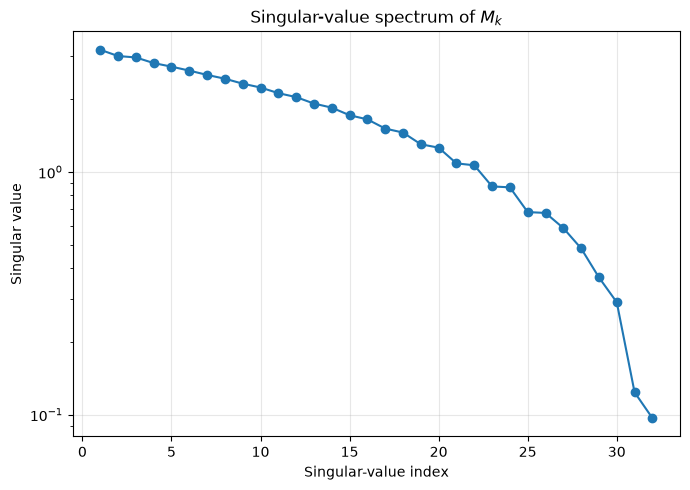

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.semilogy(
    np.arange(1, Nv + 1),
    singular_values,
    "o-"
)

ax.set_xlabel("Singular-value index")
ax.set_ylabel("Singular value")
ax.set_title(r"Singular-value spectrum of $M_k$")
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "singular_values_Nv32_k0p5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# ---------------------------------------------------------
# Eigenvalue analysis
# ---------------------------------------------------------

eigenvalues = eigvals(M_k)

print("First 10 eigenvalues:\n")

for lam in eigenvalues[:10]:
    print(lam)

First 10 eigenvalues:

2.9999999874227212j
(-7.174588725437827e-16+2.8064513939870483j)
(6.921572080135878e-16+2.6129016007741046j)
(2.370935441982212e-16+2.419344576034605j)
(1.3434803255347288e-15+2.2257515195649193j)
(-1.4661761615618225e-15+2.0320102346769415j)
(-1.0832676609418695e-15+1.837773896787702j)
(2.2054894109771194e-15+1.6422220571528938j)
(-1.4839373326206382e-15+1.4439303011618057j)
(1.7524184406045949e-15+1.2411456504843683j)


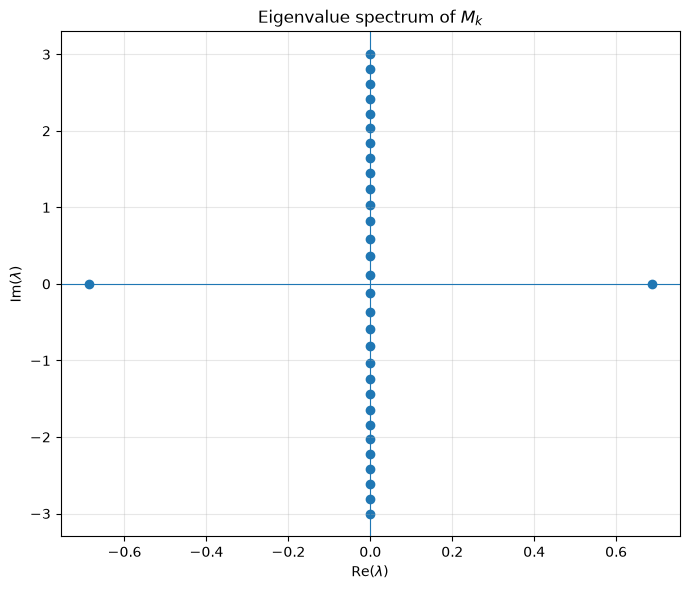

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    eigenvalues.real,
    eigenvalues.imag
)

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)

ax.set_xlabel(r"$\mathrm{Re}(\lambda)$")
ax.set_ylabel(r"$\mathrm{Im}(\lambda)$")
ax.set_title(r"Eigenvalue spectrum of $M_k$")
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "eigenvalue_spectrum_Nv32_k0p5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()